# Reach review: previous implementation versus updated code

The previous implementation and its entire local dependency closure are frozen
verbatim from clean commit `a7902c08e755212451cb5dff0ec93ee67232aa71`.
The updated implementation is imported from the working checkout. Restart the
kernel after editing it. No historical checkout or external helper is needed.

Datasets, renderer settings, bounded grid sizes, original density schedules and
all 4096 image features match `curvature_review_before_after.ipynb`: 2D quadrics,
3D/4D variants including high ambient dimensions, three graphs, all three
dSprites classes and all twenty augmented COIL-20 objects. COIL-20 uses the
existing `COIL20_PATH`; no download is performed.

**Exhaustive reach is quadratic in sampled point count.** `MAX_REACH_POINTS`
increases a common query/candidate stride for both versions; full-grid finite
differences are retained. Every row records the actual stride and candidate
count. This is a bounded reach comparison on the same underlying grids, not
an exhaustive search over every input sample. Set the cap to None deliberately
to use only `REACH_SUBSAMPLE`. The original profile includes very large input
grids even with a reach-point cap.

The default near-pair diagnostic can reject a component that previously
returned an unstable value. Errors and infinite estimates are retained in the
report; plots do not turn them into zero. An explicit positive distance filter
is an approximation and may omit real bottlenecks. The annulus probe illustrates
the formula's boundary limitation, not a corrected boundary-reach algorithm.
Generic finite-difference tangent bias remains visible in the warped-circle
convergence probes.

Outputs follow the curvature comparison: frozen/current sources and patch,
configuration/provenance, per-case pointwise NPZ arrays and witnesses, CSV/JSON,
numerical/runtime/distribution figures, and a plain Markdown run report directly
after the final plots. Unique aware timestamps preserve earlier runs. CUDA is
the default and never silently falls back to CPU.

In [1]:
from pathlib import Path
from time import perf_counter
from statistics import median
from datetime import datetime
from zoneinfo import ZoneInfo
from contextlib import redirect_stderr
import builtins
import hashlib
import io
import importlib.metadata
import json
import math
import platform
import subprocess
import sys
import types

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PACKAGE_ROOT = next(candidate for p in (Path.cwd(), *Path.cwd().parents)
                    for candidate in (p, p / "manifold-microscope")
                    if (candidate / "microscope/computations_grid/reach.py").is_file())
sys.path.insert(0, str(PACKAGE_ROOT))
from microscope.computations_grid import reach as current_reach
from microscope.datasets import custom_dsprites, coil20
from microscope.manifold_examples.ellipsoid import ellipsoid_scalar_curvature
from microscope.manifold_examples.hyperboloid import hyperboloid_scalar_curvature
from microscope.manifold_examples.sphere import sphere_scalar_curvature
from microscope.manifold_examples.sampling_grid import sample_ellipsoid_on_grid, sample_hyperboloid_on_grid
from microscope.cyclic_dimensions import get_difference_intervals

PROFILE = "bounded"  # "bounded" or the curvature notebook's "original" grids.
DEVICE = "cuda:0"  # Set "cpu" explicitly for the CPU baseline.
DTYPE = np.float32
REPEATS = 2
CPU_THREADS = 2
REACH_BATCH_SIZE = 8
CANDIDATE_BATCH_SIZE = 1024
REACH_SUBSAMPLE = 1
MAX_REACH_POINTS = 64  # None disables the automatic common stride increase.
MIN_PAIR_DISTANCE = None  # Updated API default diagnostic; explicit cutoff opts into filtering.
INCLUDE_FULL_DSPRITES = True
N_SIZES = 10
SEED = 0
APPLY_RANDOM_ISOMETRY = False
INCLUDE_TOTAL_TEST_GRID = True
INCLUDE_SLOW_TESTS = True
SLOW_CASE_NAMES = None

assert PROFILE in ("bounded", "original") and REPEATS >= 1
assert MAX_REACH_POINTS is None or MAX_REACH_POINTS >= 2
if str(DEVICE).startswith("cuda") and not torch.cuda.is_available():
    raise RuntimeError("Requested CUDA is unavailable; select CPU explicitly.")
torch.set_num_threads(CPU_THREADS)
np.random.seed(SEED)
REPORT_TIMEZONE = "Europe/Berlin"
RUN_STARTED_AT = datetime.now(ZoneInfo(REPORT_TIMEZONE))
RUN_ID = RUN_STARTED_AT.strftime("%Y%m%dT%H%M%S_%f%z")
OUTPUT_DIR = PACKAGE_ROOT.parent / "outputs/REACH_REVIEW" / RUN_ID / PROFILE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREVIOUS_SOURCES, PREVIOUS_HASHES = {}, {}

## Frozen previous implementation and matching helpers

Each source is verbatim and SHA-256 checked before execution in an isolated namespace.

### `microscope._grid_validation`

SHA-256: `3fbe67ced2b01f348f2ef5da08635cc3adbe7656c290a732ce953e1189758b29`.

In [2]:
PREVIOUS_SOURCES['microscope._grid_validation'] = r'''"""Validation shared by regular-grid sampling and computations."""
import numpy as np


def integer_list(values, name, *, minimum=0):
    try:
        values = list(values)
    except TypeError as error:
        raise ValueError(f"{name} must be a sequence of integers.") from error
    if any(isinstance(v, (bool, np.bool_)) or not isinstance(v, (int, np.integer))
           or v < minimum for v in values):
        raise ValueError(f"{name} must contain integers >= {minimum}.")
    return [int(v) for v in values]


def cyclic_axes(values, dims):
    axes = integer_list(values, "cyclic dimensions")
    if len(set(axes)) != len(axes) or any(axis >= dims for axis in axes):
        raise ValueError(f"cyclic dimensions must be unique axes in [0, {dims}).")
    return axes


def spacings(values, dims):
    """Validate real finite nonzero spacings, preserving each scalar's type."""
    try:
        values = list(values)
        array = np.asarray(values)
    except (TypeError, ValueError) as error:
        raise ValueError("difference intervals must be finite nonzero spacings.") from error
    if array.ndim != 1 or len(array) != dims:
        raise ValueError(f"Expected {dims} difference intervals, one spacing per grid axis.")
    if (array.dtype.kind not in "iuf" or any(isinstance(v, (bool, np.bool_)) for v in values)
            or not np.isfinite(array).all() or np.any(array == 0)):
        raise ValueError("difference intervals must be finite nonzero spacings.")
    return values
'''
PREVIOUS_HASHES['microscope._grid_validation'] = '3fbe67ced2b01f348f2ef5da08635cc3adbe7656c290a732ce953e1189758b29'

### `microscope.cyclic_dimensions`

SHA-256: `01feeeddab6c64331775f04ae7ea6ecb780c5a170d45daeb1055596b941b9d5c`.

In [3]:
PREVIOUS_SOURCES['microscope.cyclic_dimensions'] = r'''import numpy as np

from microscope._grid_validation import cyclic_axes, integer_list, spacings


def pad_cyclic_dimensions(
        array: np.ndarray,
        cyclic_dimensions: list[int],
        pad_sizes: list[int]
) -> np.ndarray:
    """Pad an array on both sides along cyclic dimensions in a circular way.

    Args:
        array: The array to pad.
        cyclic_dimensions: The dimensions along which to pad.
        pad_sizes: The size of the padding per cyclic dimension. It will be applied on both sides,
            i.e. the array will grow by 2*pad_size.

    Returns:
        The padded array.
    """
    cyclic_dimensions = cyclic_axes(cyclic_dimensions, array.ndim)
    pad_sizes = integer_list(pad_sizes, "pad sizes")
    if len(cyclic_dimensions) != len(pad_sizes):
        raise ValueError(
            f"Expected the number of cyclic dimensions ({len(cyclic_dimensions)}) to equal the number"
            f"of pad sizes ({len(pad_sizes)})."
        )
    padding = [(0, 0)]*array.ndim
    for dim, pad_size in zip(cyclic_dimensions, pad_sizes):
        if array.shape[dim] == 0:
            raise ValueError("Cannot wrap an empty cyclic axis.")
        padding[dim] = (pad_size, pad_size)
    return np.pad(array, padding, mode="wrap") if any(pad_sizes) else array


def get_difference_intervals(
        n_samples_per_dim: list[int],
        range_sizes: list[float],
        cyclic_dimensions: list[int]
) -> list[float]:
    """Computes the finite difference corresponding to the different dimensions. The difference is constant for all
    intervals and computed by dividing the range size with the number of samples if the dimension is cyclic else the
    number of samples minus 1.

    Args:
        n_samples_per_dim: The number of samples per dimension of the data.
        range_sizes: The value ranges along each dimension.
        cyclic_dimensions: Zero-based indices of the periodic grid axes.

    Returns:
        A list with the difference interval per dimension.
    """
    n_samples_per_dim = integer_list(n_samples_per_dim, "sample counts", minimum=1)
    cyclic_dimensions = cyclic_axes(cyclic_dimensions, len(n_samples_per_dim))
    range_sizes = spacings(range_sizes, len(n_samples_per_dim))
    if any(n < 2 for axis, n in enumerate(n_samples_per_dim) if axis not in cyclic_dimensions):
        raise ValueError("Noncyclic axes need at least two samples to define a spacing.")
    return [
        size / n_samples
        if dim in cyclic_dimensions
        else size / (n_samples - 1)

        for dim, [size, n_samples]
        in enumerate(zip(range_sizes, n_samples_per_dim))
    ]
'''
PREVIOUS_HASHES['microscope.cyclic_dimensions'] = '01feeeddab6c64331775f04ae7ea6ecb780c5a170d45daeb1055596b941b9d5c'

### `microscope.patches`

SHA-256: `72609d753447555c0311c09739afec0c5b8ad3f20ad03ee7c12a787fe1b8a77a`.

In [4]:
PREVIOUS_SOURCES['microscope.patches'] = r'''from typing import Optional

import numpy as np
from einops import einops

from microscope.cyclic_dimensions import pad_cyclic_dimensions
from microscope._grid_validation import cyclic_axes, integer_list


def _iter_patches_with_halo(array, patch_sizes, halo, cyclic_dimensions):
    """Yield (output slices, input tile) without padding the whole array.

    Leading grid axes use the given patch sizes. Each output tile is disjoint;
    its input includes ``halo`` samples on each side. Nonperiodic outputs lose
    that border, while periodic outputs retain every sample. Interior tiles
    are views; only tiles crossing periodic boundaries need wrapped copies.
    Trailing feature axes are untouched. Callers validate sizes and axes.
    """
    dims = len(patch_sizes)
    shape = array.shape[:dims]
    output_shape = [n if a in cyclic_dimensions else n-2*halo
                    for a, n in enumerate(shape)]
    steps = [p-2*halo for p in patch_sizes]
    counts = [(n+step-1)//step for n, step in zip(output_shape, steps)]
    for index in np.ndindex(*counts):
        starts = [i*step for i, step in zip(index, steps)]
        lengths = [min(step, n-start) for step, n, start
                   in zip(steps, output_shape, starts)]
        source, wrapped = [], []
        for axis, (start, length, n) in enumerate(zip(starts, lengths, shape)):
            first = start-halo if axis in cyclic_dimensions else start
            last = first+length+2*halo
            if first >= 0 and last <= n:
                source.append(slice(first, last))
            else:
                source.append(slice(None))
                wrapped.append((axis, np.arange(first, last) % n))
        if wrapped:
            # Gather all axes together: sequential np.take calls would retain
            # entire other wrapped axes in intermediate copies at corners.
            coordinates = dict(wrapped)
            indices = [coordinates[a] if a in coordinates else np.arange(s.start, s.stop)
                       for a, s in enumerate(source)]
            patch = array[np.ix_(*indices)]
        else:
            patch = array[tuple(source)]
        destination = tuple(slice(start, start+length)
                            for start, length in zip(starts, lengths))
        yield destination, patch


def extract_patches(
        array: np.ndarray,
        patch_sizes: list[int],
        overlaps: list[int],
        cyclic_dimensions: Optional[list[int]] = None,
        verbose: bool = False
) -> np.ndarray:
    """
    Generalized function to extract overlapping patches from the first n - d dimensions of a multidimensional array,
    leaving the last d dimensions untouched. If size of the array is not divisible by the resulting step size
    along all spatial dimensions, it will be wrap-padded to a compatible size. This means that the caller
    is responsible to truncate outputs on a later stage to compensate for those artificial padded values.

    Args:
        array: The input array to split.
        patch_sizes: The size of each patch along the first n - d dimensions.
        overlaps: The overlap along each of the first n - d dimensions.
        cyclic_dimensions: A set of dimensions where the grid is cyclic.
        verbose: If true it prints info and warning messages.


    Returns:
        A view of the overlapping patches, preserving their structure.
    """
    if cyclic_dimensions is None:
        cyclic_dimensions = []

    patch_sizes = integer_list(patch_sizes, "patch sizes", minimum=1)
    overlaps = integer_list(overlaps, "patch overlaps")
    n_dim = len(patch_sizes)
    if not 1 <= n_dim <= array.ndim:
        raise ValueError("patch sizes must cover between one and all array axes.")
    cyclic_dimensions = cyclic_axes(cyclic_dimensions, n_dim)
    n_features = len(array.shape) - n_dim

    if len(overlaps) != n_dim:
        raise ValueError(
            f"The shape dimensions of the patch sizes ({n_dim}) differ from the "
            f"shape dimensions of the overlaps ({len(overlaps)})."
        )
    if any(p <= overlap for p, overlap in zip(patch_sizes, overlaps)):
        raise ValueError("Each patch size must exceed its overlap.")
    if any(n == 0 or (axis not in cyclic_dimensions and n <= overlaps[axis])
           for axis, n in enumerate(array.shape[:n_dim])):
        raise ValueError("Grid axes must have a nonempty patch interior.")
    # Handle cyclic dimensions by padding the array
    array = pad_cyclic_dimensions(
        array,
        cyclic_dimensions=cyclic_dimensions,
        pad_sizes=[overlaps[dim] // 2 for dim in cyclic_dimensions]
    )

    patch_sizes = np.array(patch_sizes)
    overlaps = np.array(overlaps)
    step_sizes = patch_sizes - overlaps

    array_shape = np.array(array.shape[:n_dim])
    feature_shape = array.shape[n_dim:]

    residue = array_shape - overlaps - (step_sizes * ((array_shape - overlaps) // step_sizes))
    # noinspection PyUnresolvedReferences
    if (residue != 0).any():
        array_old_shape = array_shape
        # noinspection PyTypeChecker
        array = np.pad(
            array,
            pad_width=
            tuple((0, r) for r in ((step_sizes - residue) % step_sizes))
            + tuple(((0, 0) for _ in range(n_features))),
            mode="wrap"
        )
        array_shape = np.array(array.shape[:n_dim])
        feature_shape = array.shape[n_dim:]

        if verbose:
            print(
                f"WARNING: Array shape minus patch size {array_shape - patch_sizes} is not divisible by the step size "
                f"{step_sizes} (patch_size - overlap) along all dimensions. Zero padding the array of size "
                f"({array_old_shape}) to ({array_shape}) to compensate for that."
            )

    # Compute new shape and strides for patches
    patch_shape = tuple((array_shape - overlaps) // step_sizes) + tuple(patch_sizes) + feature_shape
    strides = array.strides
    patch_strides = (
        tuple(
            stride * step
            for stride, step
            in zip(strides[:n_dim], step_sizes))
        + strides[:n_dim]
        + strides[n_dim:]
    )
    # Extract overlapping patches using as_strided
    patches = np.lib.stride_tricks.as_strided(array, shape=patch_shape, strides=patch_strides)

    return patches


def stack_patches(patches: np.ndarray, n_features: int) -> np.ndarray:
    """
    Reconstructs an array from non-overlapping patches using einops.

    Args:
        patches: The patches arranged in a grid, with shape (g1, g2, ... p1, p2 ... n_features).
        n_features: The number of features which are not patched.

    Returns:
        An array with all the patches stacked along their corresponding dimensions.
    """
    # Number of spatial dimensions.
    n_dim = (len(patches.shape) - n_features) // 2

    # Dynamically construct einops pattern
    grid_dims = [f"grid{i}" for i in range(n_dim)]
    patch_dims = [f"patch{i}" for i in range(n_dim)]
    zipped_dims = [f"({g} {p})" for g, p in zip(grid_dims, patch_dims)]
    einops_pattern = f"{' '.join(grid_dims)} {' '.join(patch_dims)} ... -> {' '.join(zipped_dims)} ..."

    # Rearrange patches to reconstruct the array
    array = einops.rearrange(patches, einops_pattern)

    return array
'''
PREVIOUS_HASHES['microscope.patches'] = '72609d753447555c0311c09739afec0c5b8ad3f20ad03ee7c12a787fe1b8a77a'

### `microscope.computations_grid.basic`

SHA-256: `6f96aa7f335c4c53dc010b094345ba8a8c19b9b8d1710c8d34d1eb6849203821`.

In [5]:
PREVIOUS_SOURCES['microscope.computations_grid.basic'] = r'''import numpy as np
import torch

from microscope.patches import extract_patches
from microscope._grid_validation import spacings


def partial_derivative_approximation(
    tensor: torch.Tensor,
    dim: int,
    difference_intervals: float
) -> torch.Tensor:
    """Estimate a central finite difference along one equally spaced grid axis.

    Args:
        tensor: Input tensor of shape (s0, ..., s_{n-1}).
        dim: Zero-based axis to differentiate.
        difference_intervals: Scalar coordinate spacing along that axis.

    Returns:
        A tensor of shape (s0, ..., s_dim - 2, ..., s_{n-1}) on the input
        device. Only axis dim is shortened; all other axes are preserved.
    """
    difference_intervals = spacings([difference_intervals], 1)[0]
    device = tensor.device
    length = tensor.shape[dim]

    t_plus = torch.index_select(tensor, dim=dim, index=torch.arange(2, length, device=device))
    t_minus = torch.index_select(tensor, dim=dim, index=torch.arange(0, length - 2, device=device))

    return (t_plus - t_minus) / (2 * difference_intervals)


def crop_dim_borders(tensor: torch.Tensor, dims: set[int], crop: int = 1) -> torch.Tensor:
    """Crop the borders of a given set of dimensions by a given value. This can be used to ensure that tensors which
    have been cropped along different dimension during estimations can be further cropped to have the same shape.

    Args:
        tensor: The tensor to be cropped.
        dims: A set of dimensions to crop the tensor on.
        crop: A integer indicating the amount of cropping at the start and end of a dimension of the tensor.

    Returns:
        The cropped tensor.
    """
    device = tensor.device

    for d in dims:
        length = tensor.shape[d]
        tensor = torch.index_select(tensor, dim=d, index=torch.arange(crop, length - crop, device=device))

    return tensor


def partial_derivatives_across_all_dims(
    tensor: torch.Tensor,
    manifold_dim: int,
    difference_intervals: list[float]
) -> torch.Tensor:
    """Differentiate along the first manifold_dim axes of an equally spaced grid.

    Args:
        tensor: Shape (s1, ..., sk, f1, ..., fl), with k = manifold_dim.
        manifold_dim: Number of parameter axes; remaining axes are features.
        difference_intervals: One coordinate spacing per parameter axis.

    Returns:
        A tensor of shape (s1 - 2, ..., sk - 2, f1, ..., fl, k) on the
        input device. All parameter axes are cropped; pad periodic axes first."""
    if not 1 <= manifold_dim <= tensor.ndim:
        raise ValueError("manifold_dim must identify the leading grid axes.")
    difference_intervals = spacings(difference_intervals, manifold_dim)
    dim_idxs = set(range(manifold_dim))

    # This tensor had shape (s1 ... sk f1 ... fl k)
    partial_derivatives = torch.stack(
        [
            crop_dim_borders(
                partial_derivative_approximation(
                    tensor,
                    dim,
                    difference_intervals=range_size
                ),
                dim_idxs.difference({dim})
            )
            for dim, range_size in enumerate(difference_intervals)
        ],
        dim=-1
    )

    return partial_derivatives


def riemannian_metric(
        features_on_grid: torch.Tensor,
        difference_intervals: list[float]
) -> torch.Tensor:
    """Estimate the induced metric J.T @ J using central finite differences.

    Args:
        features_on_grid: Tensor of shape (s1, ..., sk, features).
        difference_intervals: One coordinate spacing per grid axis.

    Returns:
        A tensor of shape (s1 - 2, ..., sk - 2, k, k) on the input device.
        All grid axes are cropped; pad periodic axes first."""
    partial_derivatives = partial_derivatives_across_all_dims(
        features_on_grid,
        manifold_dim=len(features_on_grid.shape) - 1,
        difference_intervals=difference_intervals,
    )

    return partial_derivatives.transpose(-1, -2) @ partial_derivatives


def partial_derivatives_across_all_dims_batched(
    features_on_grid: np.ndarray,
    difference_intervals: list[float],
    patch_sizes: list[int],
    cyclic_dimensions: list[int],
    device: str | torch.device | None = None
):
    """Compute a NumPy grid's Jacobian in patches.

    Args:
        features_on_grid: Floating array of shape (s1, ..., sk, features).
        difference_intervals: One coordinate spacing per grid axis.
        patch_sizes: One patch size per grid axis, each greater than two.
        cyclic_dimensions: Zero-based periodic grid-axis indices.
        device: Torch device; None selects CUDA when available, otherwise CPU.

    Returns:
        A NumPy array of shape (s1_out, ..., sk_out, features, k), where
        s_i_out = s_i for periodic axes and s_i - 2 otherwise. The last axis
        indexes parameter derivatives. Results are detached from autograd.
    """
    if device is None:
        device = "cuda:0" if torch.cuda.is_available() else "cpu"

    dims = len(patch_sizes)
    overlaps = dims * [2]

    patches = extract_patches(
        features_on_grid,
        patch_sizes,
        overlaps,
        cyclic_dimensions=cyclic_dimensions
    )

    output_shape = tuple(s if i in cyclic_dimensions else s - 2
                         for i, s in enumerate(features_on_grid.shape[:dims]))
    derivative_array = np.empty((*output_shape, *features_on_grid.shape[dims:], dims),
                                dtype=features_on_grid.dtype)
    steps = np.asarray(patch_sizes) - 2
    for index in np.ndindex(*patches.shape[:dims]):
        patch = patches[index]
        points_pt_patch = torch.from_numpy(patch).to(device)

        volume_pred = partial_derivatives_across_all_dims(
            points_pt_patch,
            difference_intervals=difference_intervals,
            manifold_dim=dims
        ).cpu().detach().numpy()
        starts = np.asarray(index) * steps
        lengths = np.minimum(steps, np.asarray(output_shape) - starts)
        if np.all(lengths > 0):
            destination = tuple(slice(int(s), int(s + n)) for s, n in zip(starts, lengths))
            source = tuple(slice(0, int(n)) for n in lengths)
            derivative_array[destination] = volume_pred[source]

    return derivative_array

'''
PREVIOUS_HASHES['microscope.computations_grid.basic'] = '6f96aa7f335c4c53dc010b094345ba8a8c19b9b8d1710c8d34d1eb6849203821'

### `microscope.computations_grid.reach`

SHA-256: `849e5054a7e57271ef18c07b26c1b815a46ed9844e777df4edce6658a7260853`.

In [6]:
PREVIOUS_SOURCES['microscope.computations_grid.reach'] = r'''from typing import Optional, Union

import numpy as np
import torch
from einops import einops
from tqdm import tqdm

from microscope.computations_grid.basic import crop_dim_borders, partial_derivatives_across_all_dims_batched
from microscope.cyclic_dimensions import get_difference_intervals


def _distances_to_tangent_space(tangent_vectors: torch.Tensor, points: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
    tangent_vectors_T = einops.rearrange(tangent_vectors, "... m n -> ... n m")

    projection_matrix = (
        tangent_vectors
        @ torch.linalg.inv(tangent_vectors_T @ tangent_vectors)
        @ tangent_vectors_T
    )

    point_diffs = points[None] - x[:, None]
    points_tangent_projections = point_diffs @ projection_matrix
    return torch.linalg.norm(point_diffs - points_tangent_projections, dim=-1)


def _subsample_dims(tensor: torch.Tensor, take_every_k: int, dim_idxs: set[int]) -> torch.Tensor:
    for dim in dim_idxs:
        tensor = torch.index_select(
            tensor,
            dim=dim,
            index=torch.arange(0, tensor.shape[dim], step=take_every_k, device=tensor.device)
        )

    return tensor


def reach_per_point(
    features_on_grid: np.ndarray,
    range_sizes: list[float],
    patch_sizes: list[int],
    cyclic_dimensions: Optional[list[int]] = None,
    subsample_points: Optional[int] = None,
    batch_size: int = 10,
    return_witnesses: bool = False,
    device: str | torch.device | None = None
) -> Union[np.ndarray, tuple[np.ndarray, np.ndarray]]:
    """Estimate local reach from sampled pairs and finite-difference tangents.

    Uses min_{y != x} ||y - x||^2 / (2 d(y - x, T_x M)); see
    https://arxiv.org/abs/1705.04565. The minimum over x estimates global reach.

    Args:
        features_on_grid: Floating array of shape (s1, ..., sk, features).
        range_sizes: Full parameter-range length along each grid axis.
        patch_sizes: Derivative patch sizes, one per axis, each greater than two.
        cyclic_dimensions: Zero-based periodic grid-axis indices; None means none.
        subsample_points: Optional positive stride along every axis for both
            queries and candidates. Tangents are computed from the full grid.
        batch_size: Number of query points per pair-search batch.
        return_witnesses: Also return minimizing candidate indices.
        device: Torch device; None selects CUDA when available, otherwise CPU.

    Returns:
        A NumPy array of local estimates of shape (s1_out, ..., sk_out), where
        s_i_out = s_i for periodic axes and s_i - 2 otherwise. Subsampled
        estimates are repeated and truncated back to this shape.

        If return_witnesses is true, return (estimates, witnesses). The integer
        witnesses array has shape (N,), with N = prod(ceil(s_i_out / stride))
        and stride = subsample_points or 1. Each entry is a flat index into the
        cropped, subsampled point array. Witnesses are not repeated or reshaped.
    """
    if device is None:
        device = "cuda:0" if torch.cuda.is_available() else "cpu"

    if cyclic_dimensions is None:
        cyclic_dimensions = []
    if len(patch_sizes) != len(range_sizes):
        raise ValueError(f"Patch ({len(patch_sizes)}) and range ({len(range_sizes)}) should have same length.")
    dims_shape = features_on_grid.shape[:-1]
    n_dims = len(dims_shape)

    intrinsic_dim = len(dims_shape)
    dim_idxs = set(np.arange(intrinsic_dim))

    features_on_grid_pt = torch.from_numpy(features_on_grid)
    features_on_grid_cropped = crop_dim_borders(features_on_grid_pt, dim_idxs.difference(cyclic_dimensions))
    cropped_grid_shape = features_on_grid_cropped.shape[:-1]

    if subsample_points is not None:
        features_on_grid_cropped = _subsample_dims(features_on_grid_cropped, subsample_points, dim_idxs)

    features_on_grid_cropped_flat = features_on_grid_cropped.reshape(-1, features_on_grid_cropped.shape[-1]).to(device)

    difference_intervals = get_difference_intervals(
        n_samples_per_dim=list(dims_shape),
        range_sizes=range_sizes,
        cyclic_dimensions=cyclic_dimensions
    )
    tangent_vectors = torch.from_numpy(partial_derivatives_across_all_dims_batched(
        features_on_grid,
        cyclic_dimensions=cyclic_dimensions,
        difference_intervals=difference_intervals,
        patch_sizes=patch_sizes,
        device=device
    ))

    if subsample_points is not None:
        tangent_vectors = _subsample_dims(tangent_vectors, subsample_points, dim_idxs)

    tangent_vectors_flat = tangent_vectors.reshape(-1, *tangent_vectors.shape[-2:])

    reach_estimates = []
    estimate_witnesses = []
    num_ranges = len(features_on_grid_cropped_flat) // batch_size
    iteration_batch_ranges = [
        (i*batch_size, (i + 1)*batch_size)
        for i in range(num_ranges)
    ]

    if len(features_on_grid_cropped_flat) % batch_size != 0:
        iteration_batch_ranges += [(batch_size*num_ranges, len(features_on_grid_cropped_flat))]

    for s, e in tqdm(iteration_batch_ranges, desc=f'Reach ({device})', unit='batch'):
        x = features_on_grid_cropped_flat[s:e].to(device)
        T_x = tangent_vectors_flat[s:e].to(device)
        d_y_tang_x = _distances_to_tangent_space(T_x, features_on_grid_cropped_flat, x)

        x_estimate = torch.linalg.norm(x[:, None] - features_on_grid_cropped_flat[None], dim=-1)**2 / (2*d_y_tang_x)
        # Here x is included on the points to compare with. To make sure this pair is not picked,
        # we assign to it the largest possible value.
        max_value = float(10 * (torch.nan_to_num(x_estimate) + 1).max())
        x_estimate = torch.nan_to_num(x_estimate, nan=max_value)

        estimate_witnesses.append(torch.argmin(x_estimate, dim=-1).cpu().numpy())
        reach_estimates.append(x_estimate.min(dim=-1)[0].cpu().detach())

    reach_estimates = np.concatenate(reach_estimates, axis=0)
    estimate_witnesses = np.concatenate(estimate_witnesses, axis=0)

    grid_reach_estimates = reach_estimates.reshape(features_on_grid_cropped.shape[:-1])

    # If the reach has been computed on subsample points, repeat the values to get the original shape.
    if subsample_points is not None:
        dim_variables = [f'i{i}' for i in range(n_dims)]
        repeat_variables = [f'r{i}' for i in range(n_dims)]
        repeat_pattern = [f'({d} {r})' for d, r in zip(dim_variables, repeat_variables)]
        grid_reach_estimates = einops.repeat(
            grid_reach_estimates,
            f"{' '.join(dim_variables)} -> {' '.join(repeat_pattern)}",
            **{r: subsample_points for r in repeat_variables}
            )
        # Repetition can overshoot dimensions not divisible by the subsampling step.
        grid_reach_estimates = grid_reach_estimates[tuple(slice(0, s) for s in cropped_grid_shape)]

    if return_witnesses:
        return grid_reach_estimates, estimate_witnesses
    else:
        return grid_reach_estimates
'''
PREVIOUS_HASHES['microscope.computations_grid.reach'] = '849e5054a7e57271ef18c07b26c1b815a46ed9844e777df4edce6658a7260853'

In [7]:
def load_frozen_modules(sources, hashes):
    modules = {}
    def frozen_import(name, globals=None, locals=None, fromlist=(), level=0):
        if name in modules:
            return modules[name]
        return builtins.__import__(name, globals, locals, fromlist, level)
    for name, source in sources.items():
        assert hashlib.sha256(source.encode()).hexdigest() == hashes[name]
        module = types.ModuleType("previous_" + name)
        module.__dict__["__builtins__"] = dict(vars(builtins), __import__=frozen_import)
        modules[name] = module
        exec(compile(source, "<previous " + name + ">", "exec"), module.__dict__)
    return modules

previous_modules = load_frozen_modules(PREVIOUS_SOURCES, PREVIOUS_HASHES)
previous_reach = previous_modules["microscope.computations_grid.reach"]
assert previous_reach.partial_derivatives_across_all_dims_batched is previous_modules["microscope.computations_grid.basic"].partial_derivatives_across_all_dims_batched
assert previous_modules["microscope.computations_grid.basic"].extract_patches is previous_modules["microscope.patches"].extract_patches
assert previous_modules["microscope.cyclic_dimensions"].spacings is previous_modules["microscope._grid_validation"].spacings
assert previous_reach.reach_per_point is not current_reach.reach_per_point
assert Path(current_reach.__file__).resolve().is_relative_to(PACKAGE_ROOT.resolve())
METHODS = {"previous": previous_reach.reach_per_point, "updated": current_reach.reach_per_point}

def git_output(*args):
    return subprocess.check_output(["git", "-C", str(PACKAGE_ROOT), *args], text=True).strip()

current_hashes = {}
for name in [*PREVIOUS_SOURCES, "microscope.computations_grid._curvature_geometry"]:
    relative = Path(name.replace(".", "/") + ".py")
    source = (PACKAGE_ROOT / relative).read_text()
    current_hashes[name] = hashlib.sha256(source.encode()).hexdigest()
    path = OUTPUT_DIR / "current_sources" / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source)
for name, source in PREVIOUS_SOURCES.items():
    path = OUTPUT_DIR / "previous_sources" / (name.replace(".", "/") + ".py")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source)
metadata = dict(run_id=RUN_ID, started_at=RUN_STARTED_AT.isoformat(), report_timezone=REPORT_TIMEZONE,
    profile=PROFILE, device=str(DEVICE), dtype=np.dtype(DTYPE).name, repeats=REPEATS,
    warmup_calls=1, cpu_threads=CPU_THREADS, seed=SEED, output_dir=str(OUTPUT_DIR),
    previous_commit="a7902c08e755212451cb5dff0ec93ee67232aa71", previous_hashes=PREVIOUS_HASHES,
    current_commit=git_output("rev-parse", "HEAD"), dirty=git_output("status", "--short"),
    current_hashes=current_hashes, python=sys.version, interpreter=sys.executable,
    platform=platform.platform(), numpy=np.__version__, torch=torch.__version__, cuda_build=torch.version.cuda,
    packages={name: importlib.metadata.version(name) for name in ["numpy", "torch", "einops", "tqdm",
        "opencv-python", "Pillow", "scipy", "matplotlib", "pandas", "nbformat"]},
    float32_matmul_precision=torch.get_float32_matmul_precision(),
    allow_tf32=torch.backends.cuda.matmul.allow_tf32,
    configuration=dict(reach_batch_size=REACH_BATCH_SIZE, candidate_batch_size=CANDIDATE_BATCH_SIZE,
        reach_subsample=REACH_SUBSAMPLE, max_reach_points=MAX_REACH_POINTS,
        min_pair_distance=MIN_PAIR_DISTANCE, include_full_dsprites=INCLUDE_FULL_DSPRITES,
        n_sizes=N_SIZES, apply_random_isometry=APPLY_RANDOM_ISOMETRY))
if str(DEVICE).startswith("cuda"):
    metadata["device_name"] = torch.cuda.get_device_name(DEVICE)
    metadata["device_memory_bytes"] = torch.cuda.get_device_properties(DEVICE).total_memory
else:
    metadata["device_name"] = platform.processor() or platform.machine()
(OUTPUT_DIR / "source.patch").write_text(git_output("diff", "--binary") + "\n")

## The curvature notebook's dataset definitions

The next three cells are copied verbatim. Curvature reference arrays from `sample_case` are unused here; known reach references are supplied separately.

In [8]:
# 2D quadric cases; irregular-grid duplicates are omitted.
CASES_2D = {
    "sphere": dict(kind="ellipsoid", axes=[2, 2, 2], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "ellipsoid": dict(kind="ellipsoid", axes=[1, 1.5, 3], maximum=(1006, 1000), patches=[56, 56], fraction=.8),
    "hyperboloid": dict(kind="hyperboloid", axes=[5, 1, 3], maximum=(1006, 1000), patches=[56, 56]),
}
if INCLUDE_TOTAL_TEST_GRID:
    for name, axes in (("sphere / total-test grid", [2, 2, 2]),
                       ("ellipsoid / total-test grid", [1, 1.5, 3])):
        CASES_2D[name] = dict(kind="ellipsoid", axes=axes, maximum=(10223, 10344),
                             patches=[1034, 1042], fraction=.9999)

GRAPH_CASES = {
    name: dict(kind="graph", graph=graph, maximum=(512, 512), patches=[56, 56])
    for name, graph in (("quartic", "quartic"), ("Gaussian", "gaussian"), ("rippled", "rippled"))
}


def grid_sizes(maximum, count=N_SIZES):
    sizes = np.rint(np.geomspace(16, np.asarray(maximum), count)).astype(int)
    sizes[-1] = maximum
    assert len({tuple(pair) for pair in sizes}) == count
    return [tuple(pair) for pair in sizes]


# Exact slow-test axes, maxima, ambient dimensions, and patch sizes.
SLOW_CASE_SPECS = {}
for ambient in (4, 100, 4096):
    SLOW_CASE_SPECS[f"3D ellipsoid / ambient {ambient}"] = dict(
        kind="ellipsoid", axes=[1, 1.5, 3, 1.8], ambient=ambient,
        maximum=(56, 56, 50) if ambient > 100 else (106, 106, 100),
        patches=[16]*3, fraction=.8)
for ambient in (4, 100):
    SLOW_CASE_SPECS[f"3D hyperboloid / ambient {ambient}"] = dict(
        kind="hyperboloid", axes=[5, 1, 3, 1], ambient=ambient,
        maximum=(156, 156, 150), patches=[56]*3)
for ambient in (5, 10):
    SLOW_CASE_SPECS[f"4D sphere / ambient {ambient}"] = dict(
        kind="sphere", axes=[2]*5, ambient=ambient,
        maximum=(106, 106, 106, 100), patches=[16]*4, fraction=.8)
selected = list(SLOW_CASE_SPECS) if SLOW_CASE_NAMES is None else SLOW_CASE_NAMES
SLOW_CASES = ({name: SLOW_CASE_SPECS[name] for name in selected}
              if INCLUDE_SLOW_TESTS else {})


def graph_height_and_curvature(u, v, graph):
    # For X=(u,v,f(u,v)), R=2*(f_uu*f_vv-f_uv**2)/(1+f_u**2+f_v**2)**2.
    # Differentiate each explicit height analytically, independently of the stencil.
    if graph == "quartic":
        height = .2*u**4 + .3*v**4 + .1*u*v
        fu, fv = .8*u**3 + .1*v, 1.2*v**3 + .1*u
        fuu, fvv, fuv = 2.4*u**2, 3.6*v**2, .1
    elif graph == "gaussian":
        height = .7*np.exp(-2*(u*u + v*v))
        fu, fv = -4*u*height, -4*v*height
        fuu, fvv, fuv = (16*u*u - 4)*height, (16*v*v - 4)*height, 16*u*v*height
    elif graph == "rippled":
        height = .2*np.sin(2*u) + .15*np.cos(3*v) + .1*u*v
        fu, fv = .4*np.cos(2*u) + .1*v, -.45*np.sin(3*v) + .1*u
        fuu, fvv, fuv = -.8*np.sin(2*u), -1.35*np.cos(3*v), .1
    else:
        raise ValueError(f"Unknown graph: {graph}")
    truth = 2*(fuu*fvv - fuv**2)/(1 + fu**2 + fv**2)**2
    return height, truth


def sample_case(spec, sizes):
    dim = len(sizes)
    if spec["kind"] == "graph":
        coordinates = [np.linspace(-1., 1., num=n) for n in sizes]
        u, v = np.meshgrid(*coordinates, indexing="ij")
        height, truth = graph_height_and_curvature(u, v, spec["graph"])
        points = np.stack([u, v, height], axis=-1)
        if APPLY_RANDOM_ISOMETRY:
            # Fixed rigid transform across resolutions for comparable roundoff.
            rng = np.random.default_rng(SEED)
            rotation, _ = np.linalg.qr(rng.normal(size=(3, 3)))
            points = points @ rotation + rng.uniform(-1., 1., size=3)
        return (points.astype(DTYPE, copy=False), truth[3:-3, 3:-3],
                [2/(n - 1) for n in sizes], [])
    cyclic_dimensions = [dim - 1]
    ambient = spec.get("ambient", dim + 1)
    if APPLY_RANDOM_ISOMETRY:
        # The sampler's translation uses NumPy's global RNG, in addition to seed.
        np.random.seed(SEED)
    sampling = dict(semi_axes=spec["axes"], n_samples_per_dim=list(sizes),
                    ambient_space_dim=ambient,
                    apply_random_isometry=APPLY_RANDOM_ISOMETRY, seed=SEED)
    if spec["kind"] in ("ellipsoid", "sphere"):
        points, axes, phis, _ = sample_ellipsoid_on_grid(
            **sampling, fraction_of_angles=spec["fraction"])
        range_sizes = [(2*spec["fraction"] - 1)*np.pi]*(dim - 1) + [2*np.pi]
        truth = (sphere_scalar_curvature(float(axes[0]), phis)
                 if spec["kind"] == "sphere" else ellipsoid_scalar_curvature(axes, phis))
    else:
        points, axes, phis, _ = sample_hyperboloid_on_grid(**sampling)
        range_sizes = [2.]*(dim - 1) + [2*np.pi]
        truth = hyperboloid_scalar_curvature(axes, phis)
    crop = (slice(3, -3),)*(dim - 1) + (slice(None),)
    intervals = get_difference_intervals(list(sizes), range_sizes, cyclic_dimensions)
    return points.astype(DTYPE, copy=False), truth[crop], intervals, cyclic_dimensions

In [9]:
from microscope.datasets import custom_dsprites, coil20
from microscope.computations_grid.volume import volume_element

IMAGE_WEIGHTING = "grid"  # "grid" or "volume" weighting for the mean.
INCLUDE_DSPRITES_FULL_GRID = True  # Set True to include the expensive all-strides-one run.
IMAGE_DENSITY_BINS = 60  # Normalized histogram estimate; common bins for both methods.
DSPRITES_CLASSES = None  # None = square, ellipse, heart; or e.g. ["heart"].
COIL20_CLASSES = None  # None = all 20 objects; or e.g. ["duck", "cat"].
# Axis order: (size, rotation, y, x), and (view, size, in-plane rotation).
DSPRITES_STRIDES = [(3, 2, 3, 3), (2, 2, 2, 2), (1, 2, 1, 1), (1, 1, 1, 1)]
COIL20_STRIDES = [(2, 3, 2), (2, 2, 2), (1, 2, 1), (1, 1, 1)]
IMAGE_PATCH_SIZES = {"dsprites": [10]*4, "coil20": [10]*3}

In [10]:
def image_class_grids(dataset, class_names=None):
    """Yield one component, fixed parent grid, spacings and periodic axes."""
    mapping = custom_dsprites.LABEL_MAPPING if dataset == "dsprites" else coil20.LABEL_MAPPING
    names = list(mapping.values()) if class_names is None else list(class_names)
    if not names or len(set(names)) != len(names) or not set(names) <= set(mapping.values()):
        raise ValueError(f"Select distinct classes from {list(mapping.values())}")
    if dataset == "dsprites":
        for name in names:
            # Exact balanced-renderer parameters, one class at a time to bound memory.
            images, _ = custom_dsprites.dsprites(
                image_size=64, sprite_initial_size=20, deformation_transforms_initial_size_factor=4,
                sprites=(name,), n_sizes=22, n_angles=16, min_size_ratio=.5, max_size_ratio=1.,
                max_translation=22, translation_stride=2, blur_sigma=.8,
                flat=False, scale=False, dtype=np.float32, processes=[None]*4, verbose=False)
            images = images[0]
            images += 1.
            images *= .5
            shape = images.shape[:-2]
            intervals = get_difference_intervals(list(shape), [1., 2*np.pi, 1., 1.], [1])
            yield name, images.reshape((*shape, 4096)), intervals, [1]
            del images
    elif dataset == "coil20":
        images, _ = coil20.extended_coil20(flat=False, scale=False,
                                          buffer_for_measure_estimation=3, verbose=False)
        images += 1.
        images *= .5
        shape = images.shape[1:-2]
        intervals = get_difference_intervals(list(shape), [2*np.pi, 1., 2*np.pi], [0, 2])
        for label, name in mapping.items():
            if name in names:
                yield name, images[label].reshape((*shape, 4096)), intervals, [0, 2]
    else:
        raise ValueError(f"Unknown image dataset: {dataset}")

def image_subgrid(grid, intervals, cyclic, strides):
    dim = grid.ndim - 1
    if len(strides) != dim or len(intervals) != dim:
        raise ValueError("One stride and spacing is required per varying grid coordinate.")
    for axis, stride in enumerate(strides):
        if not isinstance(stride, (int, np.integer)) or stride < 1:
            raise ValueError("Strides must be positive integers.")
        if axis in cyclic and grid.shape[axis] % stride:
            raise ValueError(f"Stride {stride} must divide periodic axis length {grid.shape[axis]}.")
        if len(range(0, grid.shape[axis], stride)) < 7:
            raise ValueError("Every sampled axis needs at least seven points for curvature.")
    selection = tuple(slice(None, None, int(s)) for s in strides) + (slice(None),)
    # No feature subsampling. Only this selected grid is promoted to computation dtype.
    points = np.ascontiguousarray(grid[selection], dtype=DTYPE)
    return points, [float(h*s) for h, s in zip(intervals, strides)]

In [11]:
def bounded_image_grids(dataset, class_names=None):
    if dataset == "dsprites":
        for name in custom_dsprites.LABEL_MAPPING.values():
            if class_names is not None and name not in class_names:
                continue
            images, _ = custom_dsprites.dsprites(
                image_size=64, sprite_initial_size=20, deformation_transforms_initial_size_factor=4,
                sprites=(name,), n_sizes=7, n_angles=16, min_size_ratio=.5, max_size_ratio=1.,
                max_translation=7, translation_stride=2, blur_sigma=.8,
                flat=False, scale=False, dtype=np.float32, processes=[None]*4, verbose=False)
            images = images[0]
            images += 1.; images *= .5
            shape = images.shape[:-2]
            intervals = get_difference_intervals(list(shape), [1., 2*np.pi, 1., 1.], [1])
            yield name, images.reshape((*shape, 4096)), intervals, [1]
            del images
    else:
        images, _ = coil20.extended_coil20(n_sizes=1, n_angles=8, flat=False, scale=False,
                                          buffer_for_measure_estimation=3, verbose=False)
        images += 1.; images *= .5
        shape = images.shape[1:-2]
        intervals = get_difference_intervals(list(shape), [2*np.pi, 1., 2*np.pi], [0, 2])
        for label, name in coil20.LABEL_MAPPING.items():
            if class_names is not None and name not in class_names:
                continue
            yield name, images[label].reshape((*shape, 4096)), intervals, [0, 2]

In [12]:
def synchronize():
    if str(DEVICE).startswith("cuda"):
        torch.cuda.synchronize(DEVICE)

def write_json(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=True,
        default=lambda v: v.item() if isinstance(v, np.generic) else str(v)) + "\n")

all_results = []
metadata["configuration"].update(mathematical_cases={"2D": CASES_2D, "slow": SLOW_CASES, "graphs": GRAPH_CASES},
    dsprites_classes=DSPRITES_CLASSES, coil20_classes=COIL20_CLASSES, image_weighting=IMAGE_WEIGHTING,
    dsprites_strides=DSPRITES_STRIDES, coil20_strides=COIL20_STRIDES, image_patches=IMAGE_PATCH_SIZES,
    timing="Median after warmup, synchronized CUDA; input preparation, weights and saving excluded.",
    baseline_candidate_search="unmodified full candidate matrix", updated_candidate_search="chunked exhaustive")
write_json(OUTPUT_DIR / "environment.json", metadata)

def save_report():
    write_json(OUTPUT_DIR / "results.json", all_results)
    pd.DataFrame(all_results).to_csv(OUTPUT_DIR / "results.csv", index=False)

def sample_stride(points, cyclic):
    shape = [n if a in cyclic else n-2 for a, n in enumerate(points.shape[:-1])]
    stride = REACH_SUBSAMPLE or 1
    while MAX_REACH_POINTS is not None and math.prod((n+stride-1)//stride for n in shape) > MAX_REACH_POINTS:
        stride += 1
    return stride

def stable_mean(values, weights=None):
    values = np.asarray(values, dtype=np.float64)
    if np.isnan(values).any():
        return float("nan")
    if np.isposinf(values).any():
        return float("inf")
    scale = np.max(np.abs(values))
    return float(np.average(values / scale, weights=weights)*scale) if scale else 0.

def compare_versions(family, name, points, intervals, cyclic, patches, truth=None,
                     common_options=None, current_options=None, expected_updated=None):
    stride = sample_stride(points, cyclic)
    ranges = [float(h*(n if a in cyclic else n-1)) for a, (h, n) in enumerate(zip(intervals, points.shape))]
    kwargs = dict(range_sizes=ranges, patch_sizes=patches, cyclic_dimensions=cyclic,
                  subsample_points=stride, batch_size=REACH_BATCH_SIZE, return_witnesses=True, device=DEVICE)
    kwargs.update(common_options or {})
    stride = kwargs["subsample_points"] or 1
    shape = [n if a in cyclic else n-2 for a, n in enumerate(points.shape[:-1])]
    row = dict(family=family, case=name, method="reach", shape=list(points.shape[:-1]),
        features=points.shape[-1], points=math.prod(points.shape[:-1]), dtype=str(points.dtype),
        device=DEVICE, patches=list(patches), spacings=list(intervals), cyclic=list(cyclic),
        subsample_points=stride, sampled_points=math.prod((n+stride-1)//stride for n in shape),
        min_pair_distance=(current_options or {}).get("min_pair_distance", MIN_PAIR_DISTANCE),
        candidate_batch_size=CANDIDATE_BATCH_SIZE, analytic_global_reach=truth,
        expected_updated=expected_updated, input_sha256=hashlib.sha256(np.ascontiguousarray(points).tobytes()).hexdigest())
    predictions, arrays = {}, {}
    weights = (volume_element(points, intervals, cyclic, patches, device=DEVICE)
               if IMAGE_WEIGHTING == "volume" and family in ("dsprites", "coil20") else None)
    order = ("previous", "updated") if len(all_results) % 2 == 0 else ("updated", "previous")
    for version in order:
        options = dict(kwargs)
        if version == "updated":
            options.update(candidate_batch_size=CANDIDATE_BATCH_SIZE, min_pair_distance=MIN_PAIR_DISTANCE)
            options.update(current_options or {})
        try:
            with redirect_stderr(io.StringIO()):
                METHODS[version](points, **options)
                times, peaks = [], []
                for _ in range(REPEATS):
                    synchronize()
                    if str(DEVICE).startswith("cuda"):
                        torch.cuda.reset_peak_memory_stats(DEVICE)
                    start = perf_counter()
                    prediction, witnesses = METHODS[version](points, **options)
                    synchronize()
                    times.append(perf_counter()-start)
                    if str(DEVICE).startswith("cuda"):
                        peaks.append(torch.cuda.max_memory_allocated(DEVICE))
            predictions[version] = prediction
            arrays[version] = prediction
            arrays[version + "_witnesses"] = witnesses
            row[version + "_seconds"] = median(times)
            row[version + "_times"] = times
            row[version + "_cuda_peak_bytes"] = max(peaks) if peaks else None
            row[version + "_status"] = ("invalid" if np.isnan(prediction).any() or np.isneginf(prediction).any()
                else "infinite" if np.isposinf(prediction).any() else "ok")
            row[version + "_mean"] = stable_mean(prediction, weights)
            row[version + "_min"] = float(prediction.min())
            row[version + "_finite_fraction"] = float(np.isfinite(prediction).mean())
            if truth is not None:
                row[version + "_analytic_min_error"] = abs(float(prediction.min())-truth)
        except (ValueError, TypeError, RuntimeError, FloatingPointError, np.linalg.LinAlgError, ZeroDivisionError) as error:
            row[version + "_status"] = "error"
            row[version + "_error"] = type(error).__name__ + ": " + str(error)
    if len(predictions) == 2:
        a, b = predictions["previous"], predictions["updated"]
        assert a.shape == b.shape
        finite = np.isfinite(a) & np.isfinite(b)
        difference = np.full(a.shape, np.nan, dtype=np.float64)
        difference[finite] = b[finite].astype(np.float64)-a[finite].astype(np.float64)
        arrays["updated_minus_previous"] = difference
        row["max_abs_difference"] = float(np.abs(difference[finite]).max()) if finite.any() else None
        row["mae_difference"] = float(np.abs(difference[finite]).mean()) if finite.any() else None
        row["finite_pair_fraction"] = float(finite.mean())
        row["equal_infinite_fraction"] = float((np.isposinf(a) & np.isposinf(b)).mean())
        row["bitwise_equal"] = a.dtype == b.dtype and a.tobytes() == b.tobytes()
        row["speedup"] = row["previous_seconds"] / row["updated_seconds"]
    row["arrays"] = f"case_{len(all_results):04d}.npz"
    np.savez_compressed(OUTPUT_DIR / row["arrays"], **arrays)
    all_results.append(row)
    save_report()
    print(f"{family}: {name}, grid={row['shape']}, stride={stride}, N={row['sampled_points']}: "
          f"previous={row['previous_status']}, updated={row['updated_status']}", flush=True)
    return row

def reach_truth(spec):
    if spec["kind"] in ("ellipsoid", "sphere"):
        return min(spec["axes"])**2/max(spec["axes"])
    if spec["kind"] == "hyperboloid":
        c, *axes = spec["axes"]
        return min(min(axes)**2/max(axes), c*c/max(axes))
    return None  # Boundary/global reach is not supplied by scalar graph curvature.

def run_math_group(specs, family):
    for name, spec in specs.items():
        dims = len(spec["maximum"])
        schedule = grid_sizes(spec["maximum"]) if PROFILE == "original" else (
            [(16,)*dims, (32,)*dims] if dims == 2 else [(8,)*dims, (10,)*dims])
        for sizes in schedule:
            points, _, intervals, cyclic = sample_case(spec, sizes)
            patches = spec["patches"] if PROFILE == "original" else [min(8, p) for p in spec["patches"]]
            compare_versions(family, name, points, intervals, cyclic, patches, reach_truth(spec))

def run_image_group(dataset):
    names = DSPRITES_CLASSES if dataset == "dsprites" else COIL20_CLASSES
    components = (image_class_grids(dataset, names) if PROFILE == "original" else bounded_image_grids(dataset, names))
    if PROFILE == "bounded":
        schedules = [(1,2,1,1), (1,1,1,1)] if dataset == "dsprites" else [(2,1,1), (1,1,1)]
    else:
        schedules = DSPRITES_STRIDES if dataset == "dsprites" else COIL20_STRIDES
        if dataset == "dsprites" and not INCLUDE_FULL_DSPRITES:
            schedules = [s for s in schedules if any(v != 1 for v in s)]
    for name, grid, intervals, cyclic in components:
        for strides in schedules:
            points, h = image_subgrid(grid, intervals, cyclic, strides)
            patches = IMAGE_PATCH_SIZES[dataset] if PROFILE == "original" else [8]*len(strides)
            compare_versions(dataset, name, points, h, cyclic, patches)
            del points
        del grid

## 2D mathematical manifolds

In [13]:
run_math_group(CASES_2D, '2D')

2D: sphere, grid=[16, 16], stride=2, N=56: previous=ok, updated=ok
2D: sphere, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok
2D: ellipsoid, grid=[16, 16], stride=2, N=56: previous=ok, updated=ok
2D: ellipsoid, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok
2D: hyperboloid, grid=[16, 16], stride=2, N=56: previous=ok, updated=ok
2D: hyperboloid, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok
2D: sphere / total-test grid, grid=[16, 16], stride=2, N=56: previous=ok, updated=ok
2D: sphere / total-test grid, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok
2D: ellipsoid / total-test grid, grid=[16, 16], stride=2, N=56: previous=ok, updated=ok
2D: ellipsoid / total-test grid, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok


## 3D / 4D manifolds and ambient dimensions

In [14]:
run_math_group(SLOW_CASES, 'slow')

slow: 3D ellipsoid / ambient 4, grid=[8, 8, 8], stride=2, N=36: previous=ok, updated=ok
slow: 3D ellipsoid / ambient 4, grid=[10, 10, 10], stride=3, N=36: previous=ok, updated=ok
slow: 3D ellipsoid / ambient 100, grid=[8, 8, 8], stride=2, N=36: previous=ok, updated=ok
slow: 3D ellipsoid / ambient 100, grid=[10, 10, 10], stride=3, N=36: previous=ok, updated=ok
slow: 3D ellipsoid / ambient 4096, grid=[8, 8, 8], stride=2, N=36: previous=ok, updated=ok
slow: 3D ellipsoid / ambient 4096, grid=[10, 10, 10], stride=3, N=36: previous=ok, updated=ok
slow: 3D hyperboloid / ambient 4, grid=[8, 8, 8], stride=2, N=36: previous=ok, updated=ok
slow: 3D hyperboloid / ambient 4, grid=[10, 10, 10], stride=3, N=36: previous=ok, updated=ok
slow: 3D hyperboloid / ambient 100, grid=[8, 8, 8], stride=2, N=36: previous=ok, updated=ok
slow: 3D hyperboloid / ambient 100, grid=[10, 10, 10], stride=3, N=36: previous=ok, updated=ok
slow: 4D sphere / ambient 5, grid=[8, 8, 8, 8], stride=3, N=24: previous=ok, update

## Quartic, Gaussian and rippled graphs

In [15]:
run_math_group(GRAPH_CASES, 'graphs')

graphs: quartic, grid=[16, 16], stride=2, N=49: previous=ok, updated=ok
graphs: quartic, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok
graphs: Gaussian, grid=[16, 16], stride=2, N=49: previous=ok, updated=ok
graphs: Gaussian, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok
graphs: rippled, grid=[16, 16], stride=2, N=49: previous=ok, updated=ok
graphs: rippled, grid=[32, 32], stride=4, N=64: previous=ok, updated=ok


## dSprites: three classes, 4D / 4096 pixels

In [16]:
run_image_group('dsprites')

dsprites: square, grid=[7, 8, 7, 7], stride=3, N=24: previous=ok, updated=ok
dsprites: square, grid=[7, 16, 7, 7], stride=3, N=48: previous=ok, updated=ok
dsprites: ellipse, grid=[7, 8, 7, 7], stride=3, N=24: previous=ok, updated=ok
dsprites: ellipse, grid=[7, 16, 7, 7], stride=3, N=48: previous=ok, updated=ok
dsprites: heart, grid=[7, 8, 7, 7], stride=3, N=24: previous=ok, updated=ok
dsprites: heart, grid=[7, 16, 7, 7], stride=3, N=48: previous=ok, updated=ok


## COIL-20: twenty objects, 3D / 4096 pixels

In [17]:
run_image_group('coil20')

coil20: duck, grid=[9, 7, 8], stride=2, N=60: previous=ok, updated=ok
coil20: duck, grid=[18, 7, 8], stride=3, N=36: previous=ok, updated=ok
coil20: wood_triangle, grid=[9, 7, 8], stride=2, N=60: previous=ok, updated=ok
coil20: wood_triangle, grid=[18, 7, 8], stride=3, N=36: previous=ok, updated=ok
coil20: car0, grid=[9, 7, 8], stride=2, N=60: previous=ok, updated=ok
coil20: car0, grid=[18, 7, 8], stride=3, N=36: previous=ok, updated=ok
coil20: cat, grid=[9, 7, 8], stride=2, N=60: previous=ok, updated=ok
coil20: cat, grid=[18, 7, 8], stride=3, N=36: previous=ok, updated=ok
coil20: anacin, grid=[9, 7, 8], stride=2, N=60: previous=ok, updated=ok
coil20: anacin, grid=[18, 7, 8], stride=3, N=36: previous=ok, updated=ok
coil20: car1, grid=[9, 7, 8], stride=2, N=60: previous=ok, updated=ok
coil20: car1, grid=[18, 7, 8], stride=3, N=36: previous=ok, updated=ok
coil20: wood_square, grid=[9, 7, 8], stride=2, N=60: previous=ok, updated=ok
coil20: wood_square, grid=[18, 7, 8], stride=3, N=36: pre

## Review counterexamples

Errors are expected on invalid, undersampled and unresolved inputs. The explicit near-pair filter is labelled separately. The annulus remains a boundary limitation, and nonlinear-angle circles illustrate retained finite-difference bias.

In [18]:
def run_review_probes():
    t = np.linspace(0, 2*np.pi, 24, endpoint=False)
    circle = 2*np.column_stack([np.cos(t), np.sin(t)])
    compare_versions("review", "single candidate", circle, [2*np.pi/24], [0], [10],
                     common_options=dict(subsample_points=24), expected_updated="error")
    line = np.column_stack([np.arange(9.), np.zeros(9)])
    compare_versions("review", "flat line", line, [1.], [], [5], expected_updated="infinite")
    u, v = np.meshgrid(np.linspace(-1, 1, 9), np.linspace(-1, 1, 9), indexing="ij")
    for dtype, eps in [(np.float32, 1e-5), (np.float64, 1e-8)]:
        plane = np.stack([u+v, eps*v, np.zeros_like(u)], axis=-1).astype(dtype)
        compare_versions("review", "full-rank skew plane / " + np.dtype(dtype).name,
                         plane, [.25]*2, [], [5]*2, expected_updated="infinite")
    compare_versions("review", "all NaN", np.full((8,2), np.nan), [2*np.pi/8], [0], [5], expected_updated="error")
    compare_versions("review", "finite float32 overflow", (circle*5e19).astype(np.float32),
                     [2*np.pi/24], [0], [10], expected_updated="error")
    compare_versions("review", "negative NumPy strides", circle[::-1], [2*np.pi/24], [0], [10], 2., expected_updated="ok")
    doubled = 2*np.column_stack([np.cos(2*t), np.sin(2*t)])
    compare_versions("review", "near-duplicate default diagnostic", doubled, [4*np.pi/24], [0], [10], 2., expected_updated="error")
    compare_versions("review", "near-duplicate explicit filter", doubled, [4*np.pi/24], [0], [10], 2.,
                     current_options=dict(min_pair_distance=1e-8), expected_updated="ok")
    for n in [16, 64, 128]:
        phi = np.linspace(0, 2*np.pi, n, endpoint=False)
        theta = phi + .8*np.sin(phi)
        points = np.column_stack([np.cos(theta), np.sin(theta)])
        compare_versions("review", f"nonlinear unit circle / n={n}", points, [2*np.pi/n], [0], [10], 1.,
                         common_options=dict(subsample_points=1), expected_updated="ok")
    r, angle = np.meshgrid(np.linspace(1,2,9), t, indexing="ij")
    annulus = np.stack([r*np.cos(angle), r*np.sin(angle), np.zeros_like(r)], axis=-1)
    compare_versions("review", "annulus boundary limitation", annulus, [.125, 2*np.pi/24], [1], [5,10],
                     1., expected_updated="infinite")

run_review_probes()

review: single candidate, grid=[24], stride=24, N=1: previous=ok, updated=error
review: flat line, grid=[9], stride=1, N=7: previous=ok, updated=infinite
review: full-rank skew plane / float32, grid=[9, 9], stride=1, N=49: previous=error, updated=infinite
review: full-rank skew plane / float64, grid=[9, 9], stride=1, N=49: previous=error, updated=infinite
review: all NaN, grid=[8], stride=1, N=8: previous=ok, updated=error
review: finite float32 overflow, grid=[24], stride=1, N=24: previous=ok, updated=error
review: negative NumPy strides, grid=[24], stride=1, N=24: previous=error, updated=ok
review: near-duplicate default diagnostic, grid=[24], stride=1, N=24: previous=ok, updated=error
review: near-duplicate explicit filter, grid=[24], stride=1, N=24: previous=ok, updated=ok
review: nonlinear unit circle / n=16, grid=[16], stride=1, N=16: previous=ok, updated=ok
review: nonlinear unit circle / n=64, grid=[64], stride=1, N=64: previous=ok, updated=ok
review: nonlinear unit circle / n=

## Numerical, runtime and pointwise output comparisons

Runtime excludes preparation, weights and serialization. CUDA peak allocated bytes are measured per call. Failures remain explicit; infinity is valid for flat reach. Difference summaries use only pairs where both outputs are finite, with that fraction recorded.

,family,case,shape,sampled_points,subsample_points,previous_status,updated_status,previous_min,updated_min,max_abs_difference,previous_seconds,updated_seconds,speedup,previous_cuda_peak_bytes,updated_cuda_peak_bytes
0,2D,sphere,"[16, 16]",56,2,ok,ok,1.999997e+00,1.999996,1.192093e-06,0.003758,0.008371,0.448995,8544768.0,8669184.0
1,2D,sphere,"[32, 32]",64,4,ok,ok,1.999990e+00,1.999991,1.311302e-06,0.007355,0.012568,0.585267,8546304.0,8669184.0
2,2D,ellipsoid,"[16, 16]",56,2,ok,ok,3.492284e-01,0.349228,2.384186e-07,0.003633,0.008319,0.436657,8544768.0,8669184.0
3,2D,ellipsoid,"[32, 32]",64,4,ok,ok,3.467615e-01,0.346762,2.384186e-07,0.007280,0.012740,0.571387,8546304.0,8669184.0
4,2D,hyperboloid,"[16, 16]",56,2,ok,ok,7.260453e-01,0.726045,1.788139e-07,0.003632,0.008299,0.437677,8544768.0,8669184.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,review,near-duplicate explicit filter,[24],24,1,ok,ok,4.143409e-15,2.000000,2.000000e+00,0.001398,0.003336,0.419200,8535040.0,8798720.0
85,review,nonlinear unit circle / n=16,[16],16,1,ok,ok,6.080284e-01,0.608028,1.332268e-15,0.001051,0.002395,0.438690,8530432.0,8797696.0
86,review,nonlinear unit circle / n=64,[64],64,1,ok,ok,8.778345e-01,0.877834,1.176836e-14,0.003259,0.008364,0.389633,8558592.0,8807424.0
87,review,nonlinear unit circle / n=128,[128],128,1,ok,ok,9.366847e-01,0.936685,1.754152e-14,0.006325,0.017237,0.366930,8596480.0,8821760.0


,family,case,previous_error,updated_error
76,review,single candidate,NaN,ValueError: Reach needs at least two distinct ...
78,review,full-rank skew plane / float32,_LinAlgError: linalg.inv: (Batch element 0): T...,NaN
79,review,full-rank skew plane / float64,_LinAlgError: linalg.inv: (Batch element 0): T...,NaN
80,review,all NaN,NaN,ValueError: Reach inputs must contain only fin...
81,review,finite float32 overflow,NaN,FloatingPointError: Tangent QR overflow at the...
82,review,negative NumPy strides,ValueError: At least one stride in the given n...,NaN
83,review,near-duplicate default diagnostic,NaN,ValueError: Unresolved near-coincident pair at...


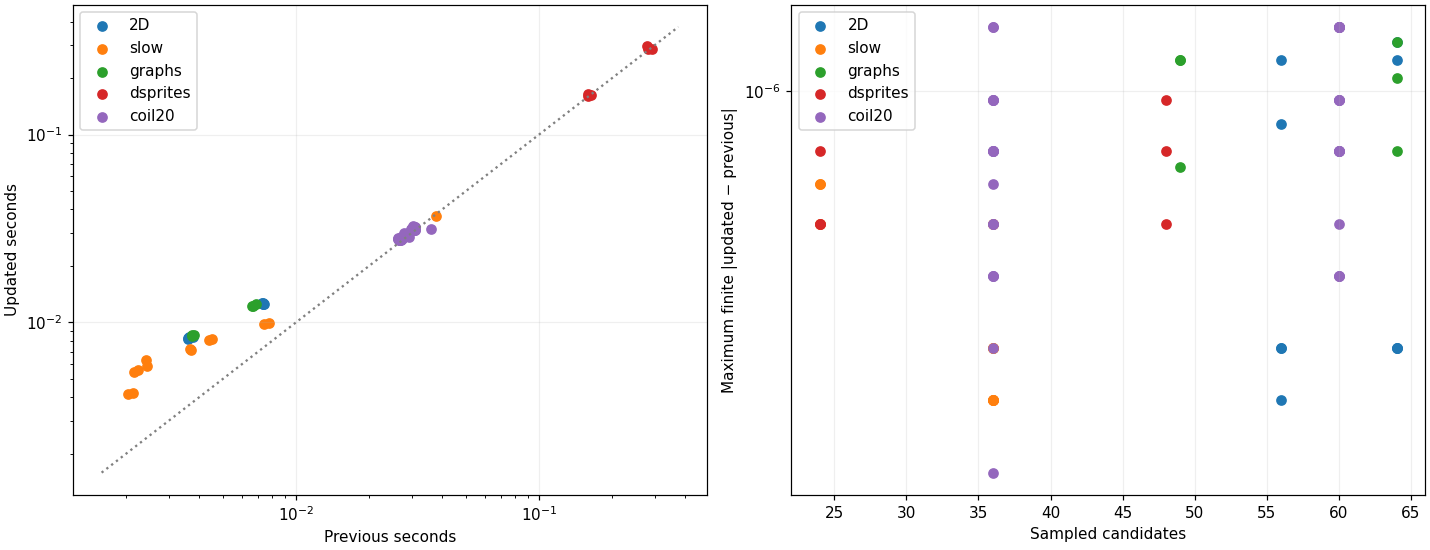

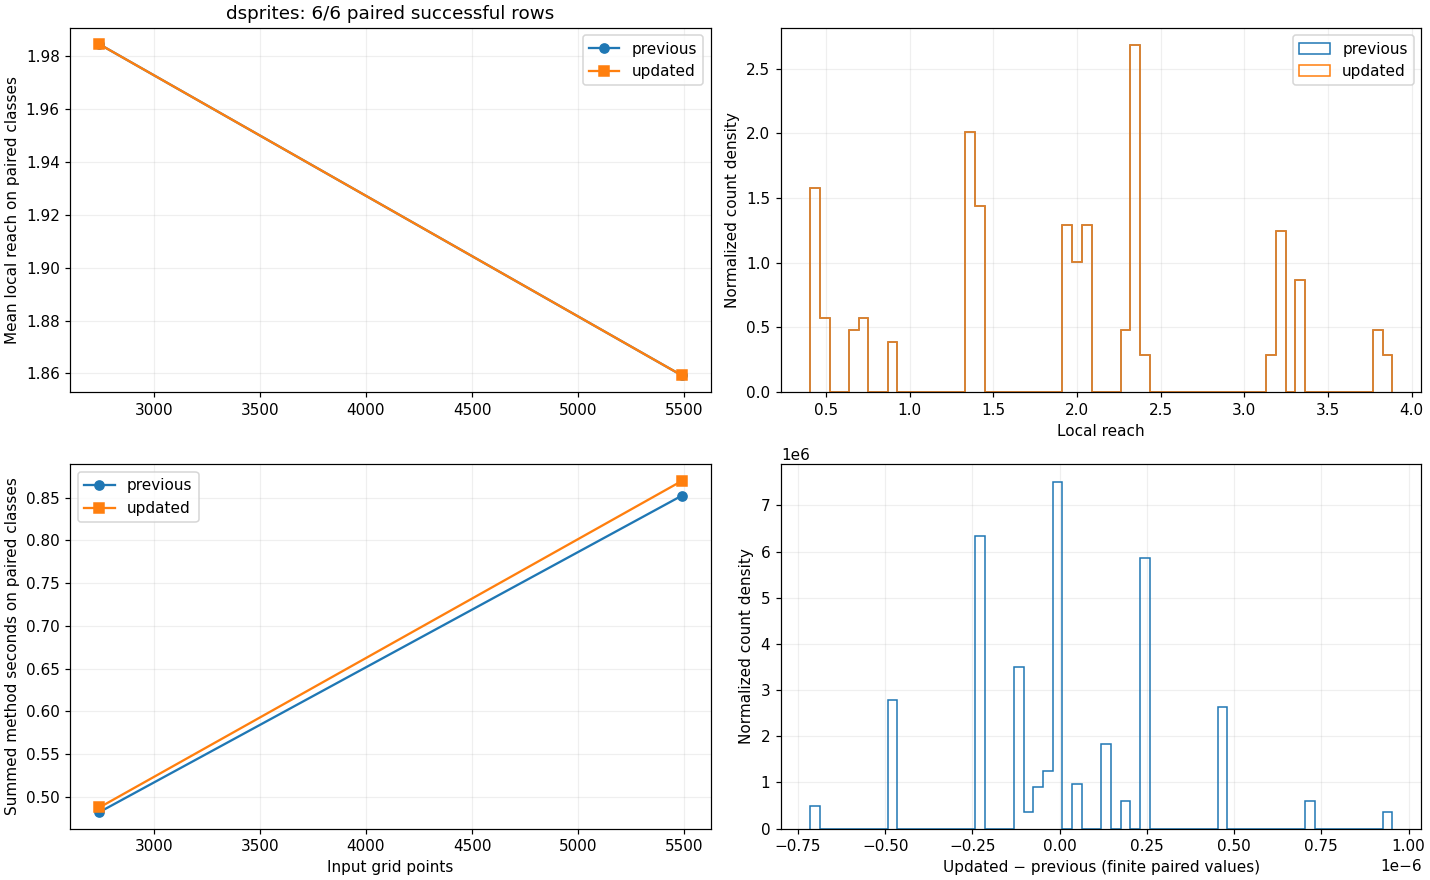

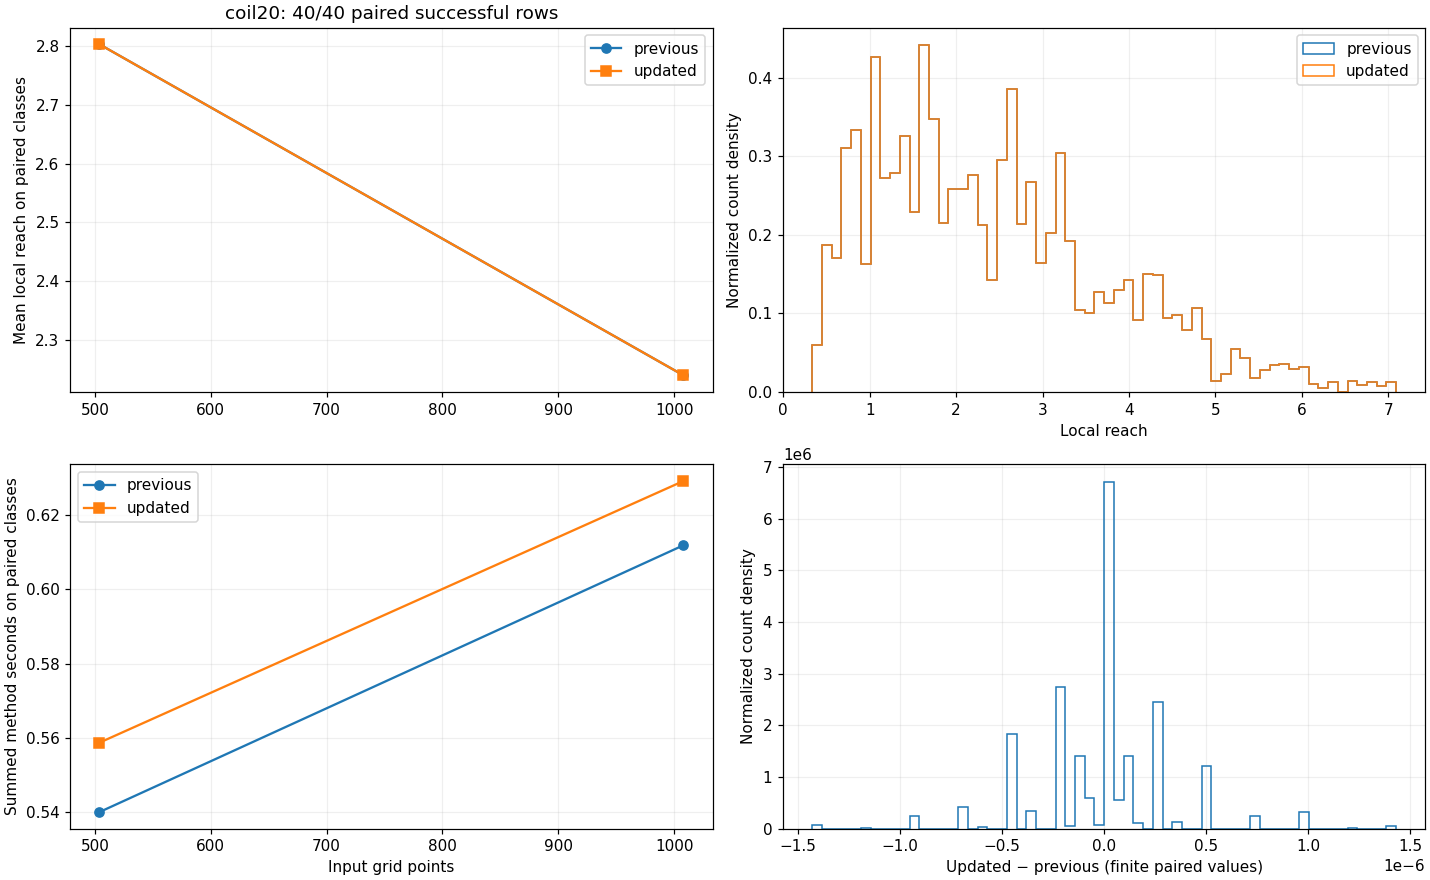

In [19]:
report = pd.DataFrame(all_results)
columns = ["family", "case", "shape", "sampled_points", "subsample_points", "previous_status", "updated_status",
    "previous_min", "updated_min", "max_abs_difference", "previous_seconds", "updated_seconds", "speedup",
    "previous_cuda_peak_bytes", "updated_cuda_peak_bytes"]
display(report.reindex(columns=columns))
display(report.loc[(report.previous_status == "error") | (report.updated_status == "error"),
                   [c for c in ["family", "case", "previous_error", "updated_error"] if c in report]])

def save_figure(name):
    plt.gcf().savefig(OUTPUT_DIR / (name + ".png"), dpi=140)
    plt.gcf().savefig(OUTPUT_DIR / (name + ".pdf"))
    plt.show()

def plot_comparisons():
    ordinary = report[report.family != "review"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for family, rows in ordinary.groupby("family", sort=False):
        paired = rows.dropna(subset=["previous_seconds", "updated_seconds"])
        axes[0].scatter(paired.previous_seconds, paired.updated_seconds, label=family)
        if "max_abs_difference" in rows:
            differences = rows.dropna(subset=["max_abs_difference"])
            axes[1].scatter(differences.sampled_points, differences.max_abs_difference, label=family)
    axes[0].set(xlabel="Previous seconds", ylabel="Updated seconds", xscale="log", yscale="log")
    limits = axes[0].get_xlim()
    axes[0].plot(limits, limits, color="grey", linestyle=":")
    axes[1].set(xlabel="Sampled candidates", ylabel="Maximum finite |updated − previous|")
    axes[1].set_yscale("symlog", linthresh=1e-8)
    for ax in axes:
        ax.legend(); ax.grid(alpha=.2)
    save_figure("runtime_and_difference")
    for dataset in ["dsprites", "coil20"]:
        rows = ordinary[ordinary.family == dataset]
        if rows.empty:
            continue
        fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
        paired_rows = rows[(rows.previous_status == "ok") & (rows.updated_status == "ok")]
        pooled = {version: [] for version in ["previous", "updated"]}
        for row in paired_rows.itertuples():
            with np.load(OUTPUT_DIR / row.arrays) as arrays:
                for version in pooled:
                    pooled[version].append(arrays[version].ravel())
        pooled = {version: np.concatenate(values) if values else np.array([])
                  for version, values in pooled.items()}
        combined = np.concatenate(list(pooled.values()))
        bins = np.histogram_bin_edges(combined, bins=IMAGE_DENSITY_BINS) if combined.size else None
        for version, marker in [("previous", "o"), ("updated", "s")]:
            good = paired_rows
            groups = good.groupby("points")
            means = groups[version+"_mean"].mean()
            times = groups[version+"_seconds"].sum()
            axes[0,0].plot(means.index, means.values, marker=marker, label=version)
            axes[1,0].plot(times.index, times.values, marker=marker, label=version)
            if pooled[version].size:
                axes[0,1].hist(pooled[version], bins=bins, density=True, histtype="step", label=version)
        differences = []
        for row in rows.itertuples():
            with np.load(OUTPUT_DIR / row.arrays) as arrays:
                if "updated_minus_previous" in arrays:
                    differences.append(arrays["updated_minus_previous"].ravel())
        if differences:
            values = np.concatenate(differences)
            values = values[np.isfinite(values)]
            if values.size:
                axes[1,1].hist(values, bins=IMAGE_DENSITY_BINS, density=True, histtype="step")
        axes[0,0].set(title=f"{dataset}: {len(paired_rows)}/{len(rows)} paired successful rows", ylabel="Mean local reach on paired classes")
        axes[1,0].set(xlabel="Input grid points", ylabel="Summed method seconds on paired classes")
        axes[0,1].set(xlabel="Local reach", ylabel="Normalized count density")
        axes[1,1].set(xlabel="Updated − previous (finite paired values)", ylabel="Normalized count density")
        for ax in axes.flat:
            ax.grid(alpha=.2)
            if ax.get_legend_handles_labels()[0]: ax.legend()
        save_figure(dataset + "_mean_runtime_distributions")

plot_comparisons()

In [20]:
# Copy this plain text into a Markdown cell to retain a human-readable run report.
def build_run_markdown(rows, run_metadata, generated_at=None):
    stamp = generated_at or datetime.now(ZoneInfo(run_metadata["report_timezone"]))
    ordinary = [r for r in rows if r["family"] != "review"]
    review = [r for r in rows if r["family"] == "review"]
    def number(value):
        return "n/a" if value is None else f"{value:.6g}"
    lines = [f"## Recorded reach comparison — {stamp.isoformat(timespec='seconds')}", "",
        f"Run `{run_metadata['run_id']}`; {len(ordinary)} ordinary comparison rows and {len(review)} review rows.",
        f"Device `{run_metadata['device']}` ({run_metadata['device_name']}); dtype `{run_metadata['dtype']}`; "
        f"medians of {run_metadata['repeats']} timed calls after one warmup.",
        f"Previous commit `{run_metadata['previous_commit']}`; updated checkout `{run_metadata['current_commit']}`.",
        f"Profile `{run_metadata['profile']}`; configuration: `{json.dumps(run_metadata['configuration'], default=str)}`.",
        f"Artifacts: `{run_metadata['output_dir']}`. Exact sources, hashes, dirty state and patch are retained.", "",
        "Both versions use the same full-grid tangents' input and query/candidate stride. The updated method uses QR, "
        "chunking and its recorded distance policy. Approximate tangents provide no unconditional true-reach bound.", "",
        "| Family | Rows | Previous errors | Updated errors | Paired timed rows | Max finite delta | Previous paired seconds | Updated paired seconds | Speedup |",
        "| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |"]
    for family in dict.fromkeys(r["family"] for r in ordinary):
        group = [r for r in ordinary if r["family"] == family]
        paired = [r for r in group if "previous_seconds" in r and "updated_seconds" in r]
        old = sum(r["previous_seconds"] for r in paired)
        new = sum(r["updated_seconds"] for r in paired)
        deltas = [r["max_abs_difference"] for r in paired if r.get("max_abs_difference") is not None]
        lines.append(f"| {family} | {len(group)} | {sum(r['previous_status']=='error' for r in group)} | "
            f"{sum(r['updated_status']=='error' for r in group)} | {len(paired)} | {number(max(deltas) if deltas else None)} | "
            f"{number(old if paired else None)} | {number(new if paired else None)} | {number(old/new if new else None)} |")
    if not ordinary:
        lines.append("\nNo ordinary results recorded.")
    lines += ["", "Errors and review behavior:"]
    for row in rows:
        if row["family"] == "review" or row["previous_status"] == "error" or row["updated_status"] == "error":
            lines.append(f"- {row['family']} / {row['case']}: previous={row['previous_status']} "
                f"(min {number(row.get('previous_min'))}), updated={row['updated_status']} "
                f"(min {number(row.get('updated_min'))}); "
                + " ".join(str(row.get(v+"_error", "")).replace("\n", " ") for v in ["previous", "updated"]))
    lines += ["", "The bounded profile retains all feature dimensions and the curvature comparison's bounded input grids; "
        "the recorded reach stride restricts queries/candidates. Original maximum grids, all-point exhaustive reach and "
        "other devices are not validated by a bounded run. The annulus is a boundary applicability counterexample; "
        "generic nonlinear-angle convergence and near-pair behavior remain separate from Gram conditioning."]
    return "\n".join(lines)

generated_report_markdown = build_run_markdown(all_results, metadata)
(OUTPUT_DIR / "run-report.md").write_text(generated_report_markdown + "\n")
print(generated_report_markdown)

## Recorded reach comparison — 2026-10-27T13:44:17+01:00

Run `20261027T134354_044048+0100`; 76 ordinary comparison rows and 13 review rows.
Device `cuda:0` (NVIDIA GeForce RTX 4090); dtype `float32`; medians of 2 timed calls after one warmup.
Previous commit `a7902c08e755212451cb5dff0ec93ee67232aa71`; updated checkout `a7902c08e755212451cb5dff0ec93ee67232aa71`.
Profile `bounded`; configuration: `{"reach_batch_size": 8, "candidate_batch_size": 1024, "reach_subsample": 1, "max_reach_points": 64, "min_pair_distance": null, "include_full_dsprites": true, "n_sizes": 10, "apply_random_isometry": false, "mathematical_cases": {"2D": {"sphere": {"kind": "ellipsoid", "axes": [2, 2, 2], "maximum": [1006, 1000], "patches": [56, 56], "fraction": 0.8}, "ellipsoid": {"kind": "ellipsoid", "axes": [1, 1.5, 3], "maximum": [1006, 1000], "patches": [56, 56], "fraction": 0.8}, "hyperboloid": {"kind": "hyperboloid", "axes": [5, 1, 3], "maximum": [1006, 1000], "patches": [56, 56]}, "sphere / total-test grid

## Recorded reach comparison — 2026-10-27T13:44:17+01:00

Run `20261027T134354_044048+0100`; 76 ordinary comparison rows and 13 review rows.
Device `cuda:0` (NVIDIA GeForce RTX 4090); dtype `float32`; medians of 2 timed calls after one warmup.
Previous commit `a7902c08e755212451cb5dff0ec93ee67232aa71`; updated checkout `a7902c08e755212451cb5dff0ec93ee67232aa71`.
Profile `bounded`; configuration: `{"reach_batch_size": 8, "candidate_batch_size": 1024, "reach_subsample": 1, "max_reach_points": 64, "min_pair_distance": null, "include_full_dsprites": true, "n_sizes": 10, "apply_random_isometry": false, "mathematical_cases": {"2D": {"sphere": {"kind": "ellipsoid", "axes": [2, 2, 2], "maximum": [1006, 1000], "patches": [56, 56], "fraction": 0.8}, "ellipsoid": {"kind": "ellipsoid", "axes": [1, 1.5, 3], "maximum": [1006, 1000], "patches": [56, 56], "fraction": 0.8}, "hyperboloid": {"kind": "hyperboloid", "axes": [5, 1, 3], "maximum": [1006, 1000], "patches": [56, 56]}, "sphere / total-test grid": {"kind": "ellipsoid", "axes": [2, 2, 2], "maximum": [10223, 10344], "patches": [1034, 1042], "fraction": 0.9999}, "ellipsoid / total-test grid": {"kind": "ellipsoid", "axes": [1, 1.5, 3], "maximum": [10223, 10344], "patches": [1034, 1042], "fraction": 0.9999}}, "slow": {"3D ellipsoid / ambient 4": {"kind": "ellipsoid", "axes": [1, 1.5, 3, 1.8], "ambient": 4, "maximum": [106, 106, 100], "patches": [16, 16, 16], "fraction": 0.8}, "3D ellipsoid / ambient 100": {"kind": "ellipsoid", "axes": [1, 1.5, 3, 1.8], "ambient": 100, "maximum": [106, 106, 100], "patches": [16, 16, 16], "fraction": 0.8}, "3D ellipsoid / ambient 4096": {"kind": "ellipsoid", "axes": [1, 1.5, 3, 1.8], "ambient": 4096, "maximum": [56, 56, 50], "patches": [16, 16, 16], "fraction": 0.8}, "3D hyperboloid / ambient 4": {"kind": "hyperboloid", "axes": [5, 1, 3, 1], "ambient": 4, "maximum": [156, 156, 150], "patches": [56, 56, 56]}, "3D hyperboloid / ambient 100": {"kind": "hyperboloid", "axes": [5, 1, 3, 1], "ambient": 100, "maximum": [156, 156, 150], "patches": [56, 56, 56]}, "4D sphere / ambient 5": {"kind": "sphere", "axes": [2, 2, 2, 2, 2], "ambient": 5, "maximum": [106, 106, 106, 100], "patches": [16, 16, 16, 16], "fraction": 0.8}, "4D sphere / ambient 10": {"kind": "sphere", "axes": [2, 2, 2, 2, 2], "ambient": 10, "maximum": [106, 106, 106, 100], "patches": [16, 16, 16, 16], "fraction": 0.8}}, "graphs": {"quartic": {"kind": "graph", "graph": "quartic", "maximum": [512, 512], "patches": [56, 56]}, "Gaussian": {"kind": "graph", "graph": "gaussian", "maximum": [512, 512], "patches": [56, 56]}, "rippled": {"kind": "graph", "graph": "rippled", "maximum": [512, 512], "patches": [56, 56]}}}, "dsprites_classes": null, "coil20_classes": null, "image_weighting": "grid", "dsprites_strides": [[3, 2, 3, 3], [2, 2, 2, 2], [1, 2, 1, 1], [1, 1, 1, 1]], "coil20_strides": [[2, 3, 2], [2, 2, 2], [1, 2, 1], [1, 1, 1]], "image_patches": {"dsprites": [10, 10, 10, 10], "coil20": [10, 10, 10]}, "timing": "Median after warmup, synchronized CUDA; input preparation, weights and saving excluded.", "baseline_candidate_search": "unmodified full candidate matrix", "updated_candidate_search": "chunked exhaustive"}`.
Artifacts: `/home/marios/chatgpt-projects/manifold-microscope-coding-extension/outputs/REACH_REVIEW/20261027T134354_044048+0100/bounded`. Exact sources, hashes, dirty state and patch are retained.

Both versions use the same full-grid tangents' input and query/candidate stride. The updated method uses QR, chunking and its recorded distance policy. Approximate tangents provide no unconditional true-reach bound.

| Family | Rows | Previous errors | Updated errors | Paired timed rows | Max finite delta | Previous paired seconds | Updated paired seconds | Speedup |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 2D | 10 | 0 | 0 | 10 | 1.3113e-06 | 0.0547929 | 0.104495 | 0.524356 |
| slow | 14 | 0 | 0 | 14 | 5.96046e-07 | 0.112751 | 0.149977 | 0.751792 |
| graphs | 6 | 0 | 0 | 6 | 1.3113e-06 | 0.0314048 | 0.0624832 | 0.502613 |
| dsprites | 6 | 0 | 0 | 6 | 9.53674e-07 | 1.33459 | 1.35723 | 0.983314 |
| coil20 | 40 | 0 | 0 | 40 | 1.43051e-06 | 1.15185 | 1.18786 | 0.969685 |

Errors and review behavior:
- review / single candidate: previous=ok (min 10), updated=error (min n/a);  ValueError: Reach needs at least two distinct sampled candidate coordinates.
- review / flat line: previous=ok (min 1.79769e+308), updated=infinite (min inf);  
- review / full-rank skew plane / float32: previous=error (min n/a), updated=infinite (min inf); _LinAlgError: linalg.inv: (Batch element 0): The diagonal element 2 is zero, the inversion could not be completed because the input matrix is singular. 
- review / full-rank skew plane / float64: previous=error (min n/a), updated=infinite (min inf); _LinAlgError: linalg.inv: (Batch element 0): The diagonal element 2 is zero, the inversion could not be completed because the input matrix is singular. 
- review / all NaN: previous=ok (min 10), updated=error (min n/a);  ValueError: Reach inputs must contain only finite values.
- review / finite float32 overflow: previous=ok (min 10), updated=error (min n/a);  FloatingPointError: Tangent QR overflow at the working dtype; rescale the embedding.
- review / negative NumPy strides: previous=error (min n/a), updated=ok (min 2); ValueError: At least one stride in the given numpy array is negative, and tensors with negative strides are not currently supported. (You can probably work around this by making a copy of your array  with array.copy().)  
- review / near-duplicate default diagnostic: previous=ok (min 4.14341e-15), updated=error (min n/a);  ValueError: Unresolved near-coincident pair at grid index (0,): separation 4.9e-16 <= 5.02e-15. Set min_pair_distance explicitly: a positive cutoff filters pairs; zero includes all distinct coordinates.
- review / near-duplicate explicit filter: previous=ok (min 4.14341e-15), updated=ok (min 2);  
- review / nonlinear unit circle / n=16: previous=ok (min 0.608028), updated=ok (min 0.608028);  
- review / nonlinear unit circle / n=64: previous=ok (min 0.877834), updated=ok (min 0.877834);  
- review / nonlinear unit circle / n=128: previous=ok (min 0.936685), updated=ok (min 0.936685);  
- review / annulus boundary limitation: previous=ok (min 5.03518e+14), updated=infinite (min inf);  

The bounded profile retains all feature dimensions and the curvature comparison's bounded input grids; the recorded reach stride restricts queries/candidates. Original maximum grids, all-point exhaustive reach and other devices are not validated by a bounded run. The annulus is a boundary applicability counterexample; generic nonlinear-angle convergence and near-pair behavior remain separate from Gram conditioning.